<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Financiado pela União Europeia** · Programa de Parceria Espacial África–UE · Reforço dos Alertas Precoces em África (SEWA)

# As próximas seis tardes no Senegal, a 9 km 🌡️
### Dados abertos e gratuitos do ECMWF · IFS 9 km · sem conta

> ⚠️ **Tradução:** este notebook foi traduzido do inglês com a ajuda de IA e revisto na medida do possível. Em caso de dúvida, prevalece a [versão inglesa](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast.ipynb). Comunique quaisquer erros no [GitHub](https://github.com/piddy376/visits-weather-notebooks/issues).

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast_pt.ipynb)

A previsão a 9 km do ECMWF (IFS) está disponível em **dados abertos**: sem registo, sem custos. Este notebook
descarrega a temperatura a 2 m para as 15:00 UTC (15:00 em Dacar) em cada um dos próximos seis dias, mostra o calor
de cada tarde em seis cidades do Senegal e cartografa a mais quente.

**O que precisa:** uma conta Google (para usar o Colab). Nenhuma outra conta, sem custos, nada para instalar. Tudo corre nos computadores da Google: os dados são descarregados lá, não no seu telemóvel
ou computador, por isso uma ligação lenta ou móvel é suficiente.

| Dados | O que este notebook usa | Licença |
|---|---|---|
| Previsão IFS do ECMWF, 9 km (0,1°) | Temperatura a 2 m às 15 UTC, seis dias, última execução | CC BY 4.0, dados abertos |

**Ferramentas:** [earthkit](https://earthkit.ecmwf.int), as ferramentas Python gratuitas e de código aberto do ECMWF para dados meteorológicos e climáticos.

*Clique em **Ambiente de execução → Executar tudo** (Runtime → Run all). A primeira execução demora alguns minutos, sobretudo para instalar as ferramentas.*

Implementado por:&nbsp;&nbsp;<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="30"/>

In [ ]:
# Instalar as ferramentas de código aberto (Colab / máquina nova). Alguns minutos da primeira vez.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots ecmwf-opendata

In [2]:
import pyproj                     # importar antes de earthkit.data (evita um erro ao fechar)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
from ecmwf.opendata import Client

DIAS = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro",
         "novembro", "dezembro"]
def dia(d): return f"{DIAS[d.weekday()]}, {d.day} de {MESES[d.month - 1]}"     # datas em português
def data_pt(d): return f"{d.day} de {MESES[d.month - 1]} de {d.year}"

## 1 · Escolher a área

In [3]:
AREA  = [17.5, -18.5, 11.5, -10.5]          # norte, oeste, sul, este: Senegal e Gâmbia
STEPS = [15 + 24 * d for d in range(6)]     # 15 UTC hoje e nos cinco dias seguintes (Dacar está em UTC)
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Descarregar a previsão a 9 km (dados abertos do ECMWF)

In [4]:
for SOURCE in ("ecmwf", "aws", "google"):      # primeiro o ECMWF, depois os espelhos na nuvem se estiver ocupado
    try:
        result = Client(SOURCE).retrieve(time=0, step=STEPS, stream="oper", type="fc", levtype="sfc",
                                         param="2t", resol="0p1", target="t2m.grib2")   # resol="0p1" = 9 km
        break
    except Exception as err:
        print(f"{SOURCE} não responde ({type(err).__name__}), a tentar o espelho seguinte")
run = result.datetime
x = ekd.from_source("file", "t2m.grib2").to_xarray()
x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
x = x.sel(latitude=slice(AREA[0] + 0.5, AREA[2] - 0.5), longitude=slice(AREA[1] - 0.5, AREA[3] + 0.5))  # pequena margem
t2m = x[list(x.data_vars)[0]] - 273.15                                            # kelvin -> °C
sdim = [d for d in t2m.dims if d not in ("latitude", "longitude")][0]
print(f"Previsão de {dia(run)} de {run.year}, execução das 00 UTC")
for k, s in enumerate(STEPS):
    v = run + dt.timedelta(hours=s)
    towns = "  ".join(f"{n} {float(t2m.isel({sdim: k}).sel(latitude=la, longitude=lo, method='nearest')):.0f}°"
                      for n, la, lo in CITIES)
    print(f"  {dia(v):30s} 15 UTC   {towns}")
hot = int(t2m.mean(["latitude", "longitude"]).argmax())                            # a tarde mais quente
day = run + dt.timedelta(hours=STEPS[hot])

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Previsão de quinta-feira, 19 de novembro de 2026, execução das 00 UTC
  quinta-feira, 19 de novembro   15 UTC   Dakar 29°  Saint-Louis 29°  Touba 36°  Tambacounda 35°  Ziguinchor 32°  Kédougou 30°
  sexta-feira, 20 de novembro    15 UTC   Dakar 30°  Saint-Louis 29°  Touba 37°  Tambacounda 36°  Ziguinchor 34°  Kédougou 31°
  sábado, 21 de novembro         15 UTC   Dakar 33°  Saint-Louis 33°  Touba 38°  Tambacounda 38°  Ziguinchor 35°  Kédougou 33°
  domingo, 22 de novembro        15 UTC   Dakar 33°  Saint-Louis 33°  Touba 38°  Tambacounda 38°  Ziguinchor 34°  Kédougou 34°
  segunda-feira, 23 de novembro  15 UTC   Dakar 32°  Saint-Louis 30°  Touba 37°  Tambacounda 37°  Ziguinchor 35°  Kédougou 34°
  terça-feira, 24 de novembro    15 UTC   Dakar 31°  Saint-Louis 27°  Touba 38°  Tambacounda 37°  Ziguinchor 35°  Kédougou 34°


## 3 · Cartografar a tarde mais quente

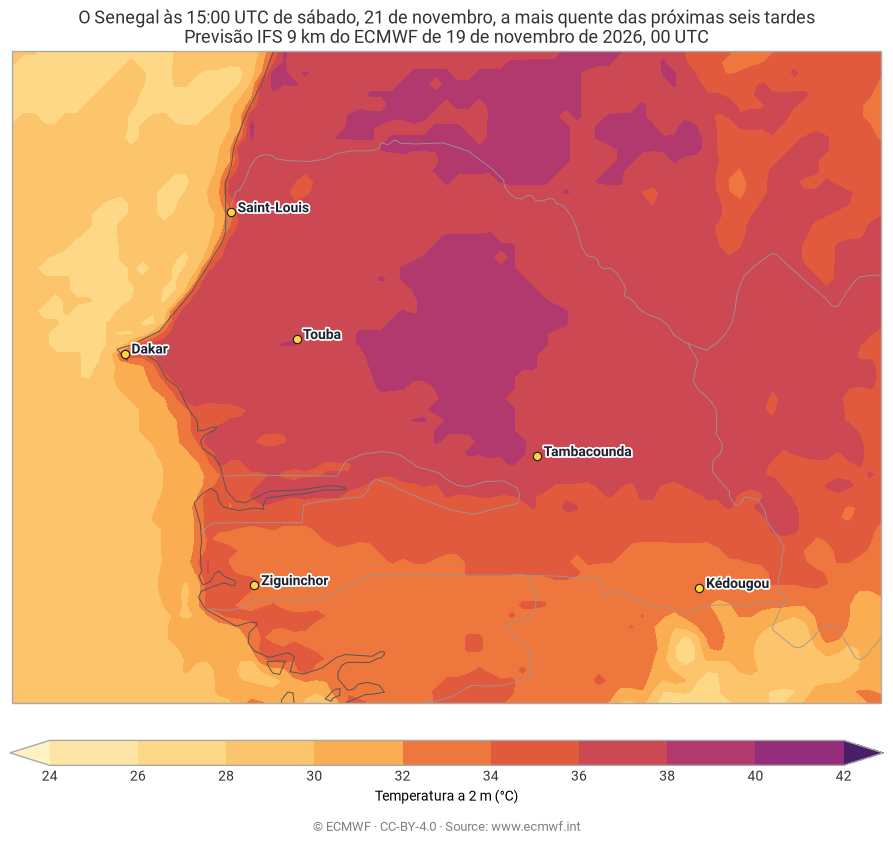

In [5]:
style = ekp.styles.Style(levels=[24, 26, 28, 30, 32, 34, 36, 38, 40, 42], colors=["#fff3c4", "#fdd27a", "#f99a3c", "#e0543e", "#a3307e", "#4a1f6a"], extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(t2m.isel({sdim: hot}), style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
label_cities(chart.ax)
chart.legend(label="Temperatura a 2 m (°C)")
chart.title(f"O Senegal às 15:00 UTC de {dia(day)}, a mais quente das próximas seis tardes\n"
            f"Previsão IFS 9 km do ECMWF de {data_pt(run)}, 00 UTC", fontsize=13)
chart.attribution("© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int")
chart.save("heat_forecast_pt.png")
chart.show()

## 4 · A sua vez 🌍

- **À noite:** troque `15` por `3` em `STEPS` para as 03 UTC, a parte mais fresca da noite.
- **O vento:** acrescente `"10u", "10v"` a `param` e desenhe setas com `chart.ax.quiver`.
- **Noutro lugar:** mude `AREA`, por exemplo `[16, -6, 9, 3]` para o Burkina Faso.

### Dados e licença
Os dados abertos do ECMWF são gratuitos sob a licença **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. Sem conta, sem chave.

[Dados abertos do ECMWF](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)